In [1]:
%run sem2.py

In [2]:
import pandas as pd
import numpy as np
import torch
from torch.utils.data import TensorDataset, DataLoader
from torch import nn
from engression.loss_func import energy_loss, energy_loss_two_sample
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv('PoliticalDemocracy.csv')
var_names = df.columns.values.tolist()
dataset = torch.tensor(df.to_numpy()).to(dtype = torch.float32)
batch_size = 25
dataloader = DataLoader(TensorDataset(dataset), batch_size = batch_size, shuffle = True)
print(var_names)

['y1', 'y2', 'y3', 'y4', 'y5', 'y6', 'y7', 'y8', 'x1', 'x2', 'x3']


In [4]:
# Linear factor model
model_formula = "x1 <- ind60 + ex1; x2 <- ind60 + ex2; x3 <- ind60 + ex3; ind60 ~ norm; ex1 ~ norm; ex2 ~ norm; ex3 ~ norm"
model = sem2(model_formula)
observed_var = ["x1", "x2", "x3"]
x = dataset[:, [var_names.index(var) for var in observed_var]]
observed_index = [list(model.static_order()).index(var) for var in observed_var]

In [5]:
optimizer = torch.optim.Adam(model.parameters(), lr=1e-2)
model.train()
for i in range(2000):
    optimizer.zero_grad()
    sample1 = model(x.size(0))[:, observed_index]
    sample2 = model(x.size(0))[:, observed_index]
    loss, s1, s2 = energy_loss_two_sample(x, sample1, sample2)
    loss.backward()
    optimizer.step()
    if i == 0 or (i + 1) % 100 == 0:
        print(f'Iter {i + 1} | loss: {loss.item():.4f}, s1: {s1.item():.4f}, s2: {s2.item():.4f}')

Iter 1 | loss: 7.7459, s1: 8.4115, s2: 1.3312
Iter 100 | loss: 5.2230, s1: 7.0448, s2: 3.6436
Iter 200 | loss: 3.7874, s1: 6.4828, s2: 5.3909
Iter 300 | loss: 2.7342, s1: 5.9115, s2: 6.3546
Iter 400 | loss: 1.9153, s1: 5.0500, s2: 6.2695
Iter 500 | loss: 1.9469, s1: 4.1681, s2: 4.4423
Iter 600 | loss: 1.5601, s1: 3.4298, s2: 3.7393
Iter 700 | loss: 1.4220, s1: 3.0415, s2: 3.2390
Iter 800 | loss: 1.1994, s1: 2.6732, s2: 2.9476
Iter 900 | loss: 1.2099, s1: 2.7648, s2: 3.1097
Iter 1000 | loss: 1.1741, s1: 2.8181, s2: 3.2880
Iter 1100 | loss: 1.4740, s1: 2.7933, s2: 2.6387
Iter 1200 | loss: 1.5043, s1: 2.7590, s2: 2.5094
Iter 1300 | loss: 1.4080, s1: 2.7080, s2: 2.6000
Iter 1400 | loss: 1.2333, s1: 2.4072, s2: 2.3478
Iter 1500 | loss: 1.2613, s1: 2.6341, s2: 2.7455
Iter 1600 | loss: 1.3025, s1: 2.5758, s2: 2.5465
Iter 1700 | loss: 1.4415, s1: 2.7242, s2: 2.5653
Iter 1800 | loss: 1.3882, s1: 2.6953, s2: 2.6142
Iter 1900 | loss: 1.5570, s1: 2.7919, s2: 2.4699
Iter 2000 | loss: 1.0918, s1: 2.

In [6]:
beta = [model.layer[node].weight[0][0].squeeze().detach().numpy().tolist() for node in observed_var]
[beta[i] / beta[0] for i in range(3)]

[1.0, 2.0521748651874225, 1.9304386347833837]

In [7]:
# # Linear factor model (same as lavaan package example)
# formula_epsx = "ex1 ~ norm; ex2 ~ norm; ex3 ~ norm;" 
# formula_epsy = "ey1 ~ norm; ey2 ~ norm; ey3 ~ norm; ey4 ~ norm; ey5 ~ norm; ey6 ~ norm; ey7 ~ norm; ey8 ~ norm;"
# formula_epsdem = "edem60 ~ norm; edem65 ~ norm;"
# formula_epscov = "e15 ~ norm; e24 ~ norm; e26 ~ norm; e37 ~ norm; e48 ~ norm; e68 ~ norm;"
# formula_end = "ind60 ~ norm; dem60 <- ind60 + edem60; dem65 <- ind60 + dem60 + edem65;"
# formula_x = "x1 <- ind60 + ex1; x2 <- ind60 + ex2; x3 <- ind60 + ex3;"
# formula_y1 = "y1 <- dem60 + ey1 + e15; y2 <- dem60 + ey2 + e24 + e26; y3 <- dem60 + ey3 + e37; y4 <- dem60 + ey4 + e24 + e48;"
# formula_y2 = "y5 <- dem65 + ey5 + e15; y6 <- dem65 + ey6 + e26; y7 <- dem65 + ey7 + e37; y8 <- dem65 + ey8 + e48 + e68"
# formula = formula_epsx + formula_epsy + formula_epsdem + formula_epscov + formula_end + formula_x + formula_y1 + formula_y2

In [8]:
# Linear factor model (without residual correlations)
formula_epsx = "ex1 ~ norm; ex2 ~ norm; ex3 ~ norm;" 
formula_epsy = "ey1 ~ norm; ey2 ~ norm; ey3 ~ norm; ey4 ~ norm; ey5 ~ norm; ey6 ~ norm; ey7 ~ norm; ey8 ~ norm;"
formula_epsdem = "edem60 ~ norm; edem65 ~ norm;"
formula_end = "ind60 ~ norm; dem60 <- ind60 + edem60; dem65 <- ind60 + dem60 + edem65;"
formula_x = "x1 <- ind60 + ex1; x2 <- ind60 + ex2; x3 <- ind60 + ex3;"
formula_y1 = "y1 <- dem60 + ey1; y2 <- dem60 + ey2; y3 <- dem60 + ey3; y4 <- dem60 + ey4;"
formula_y2 = "y5 <- dem65 + ey5; y6 <- dem65 + ey6; y7 <- dem65 + ey7; y8 <- dem65 + ey8"
formula = formula_epsx + formula_epsy + formula_epsdem + formula_end + formula_x + formula_y1 + formula_y2
lavaan_coefs = [1.483, 0.572, 0.837]

In [9]:
observed_var = var_names
x = dataset[:, [var_names.index(var) for var in observed_var]]
model = sem2(formula)
observed_index = [list(model.static_order()).index(var) for var in observed_var]

In [10]:
# vanilla energy loss minimization
model = sem2(formula)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-2)
model.train()
niter = 10000
coefs = np.zeros([niter, 3])
for i in range(niter):
    optimizer.zero_grad()
#    sample1 = model(x.size(0))[:, observed_index]
#    sample2 = model(x.size(0))[:, observed_index]
#    loss, s1, s2 = energy_loss_two_sample(x, sample1, sample2)
    sample = model(x.size(0) * 100)[:, observed_index]
    loss, s1, s2 = energy_loss(x, sample)
    loss.backward()
    optimizer.step()
    ind60_scale = model.layer["x1"].weight[0][0]
    dem60_scale = model.layer["y1"].weight[0][0]
    dem65_scale = model.layer["y5"].weight[0][0]
    coefs[i,:] = torch.tensor([model.layer["dem60"].weight[0][0] / ind60_scale * dem60_scale,
                               model.layer["dem65"].weight[0][0] / ind60_scale * dem65_scale,
                               model.layer["dem65"].weight[0][1] / dem60_scale * dem65_scale]).numpy()
    if i == 0 or (i + 1) % 1000 == 0:
        print(f'Iter {i + 1} | loss: {loss.item():.4f}, s1: {s1.item():.4f}, s2: {s2.item():.4f}')
        print(coefs[i, :])

Iter 1 | loss: 16.1459, s1: 17.3795, s2: 2.4672
[-0.11285467  0.68762678  0.3899726 ]
Iter 1000 | loss: 6.1782, s1: 12.4746, s2: 12.5929
[2.77797771 1.77334321 0.68691373]
Iter 2000 | loss: 6.0946, s1: 12.4250, s2: 12.6610
[3.34261966 1.65014303 0.65278506]
Iter 3000 | loss: 6.1677, s1: 12.5959, s2: 12.8564
[2.7360599  1.27762687 0.68863273]
Iter 4000 | loss: 6.0621, s1: 12.4450, s2: 12.7659
[1.70013249 0.76628846 0.78513801]
Iter 5000 | loss: 6.2340, s1: 12.6375, s2: 12.8071
[1.66605484 0.60171813 0.80149168]
Iter 6000 | loss: 6.1316, s1: 12.4854, s2: 12.7075
[2.19599247 0.82725298 0.78604019]
Iter 7000 | loss: 6.1366, s1: 12.4259, s2: 12.5786
[1.94374323 0.93523562 0.76329374]
Iter 8000 | loss: 6.2304, s1: 12.6225, s2: 12.7841
[2.14406085 1.02928984 0.74623901]
Iter 9000 | loss: 6.1918, s1: 12.4988, s2: 12.6139
[2.71277118 1.08481145 0.74109185]
Iter 10000 | loss: 6.1857, s1: 12.5177, s2: 12.6640
[1.6624136  0.84532458 0.78225535]


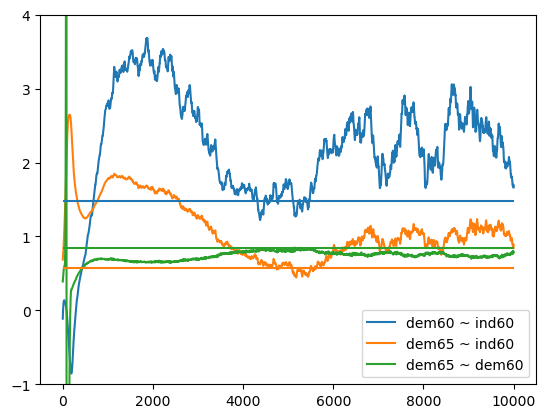

In [11]:
plt.plot(range(niter), coefs[:,0], label = "dem60 ~ ind60")
plt.plot(range(niter), coefs[:,1], label = "dem65 ~ ind60")
plt.plot(range(niter), coefs[:,2], label = "dem65 ~ dem60")
plt.hlines(lavaan_coefs, xmin = 0, xmax = niter, colors = ["C0", "C1", "C2"])
plt.ylim(-1, 4)
plt.legend()

In [12]:
# change loss function to OLS (between sample and model covariance matrices)
sample_cov = torch.cov(torch.t(x))
model = sem2(formula)
optimizer = torch.optim.Adam(model.parameters(), lr=2e-2)
model.train()
niter = 5000
coefs = np.zeros([niter, 3])
for i in range(niter):
    optimizer.zero_grad()
    model_sample = model(x.size(0) * 10)[:, observed_index]
    model_cov = torch.cov(torch.t(model_sample))
    loss = torch.norm(sample_cov - model_cov)
    loss.backward()
    optimizer.step()
    ind60_scale = model.layer["x1"].weight[0][0]
    dem60_scale = model.layer["y1"].weight[0][0]
    dem65_scale = model.layer["y5"].weight[0][0]
    coefs[i,:] = torch.tensor([model.layer["dem60"].weight[0][0] / ind60_scale * dem60_scale,
                               model.layer["dem65"].weight[0][0] / ind60_scale * dem65_scale,
                               model.layer["dem65"].weight[0][1] / dem60_scale * dem65_scale]).numpy()
    if i == 0 or (i + 1) % 1000 == 0:
        print(f'Iter {i + 1} | loss: {loss.item():.4f}, s1: {s1.item():.4f}, s2: {s2.item():.4f}')
        print(coefs[i, :])

Iter 1 | loss: 59.0162, s1: 12.5177, s2: 12.6640
[ 0.50133562  0.16269848 -0.15155098]
Iter 1000 | loss: 10.3125, s1: 12.5177, s2: 12.6640
[2.29262972 1.04278982 0.76447427]
Iter 2000 | loss: 5.6524, s1: 12.5177, s2: 12.6640
[1.37129176 0.47241285 0.83476204]
Iter 3000 | loss: 5.6939, s1: 12.5177, s2: 12.6640
[1.33933449 0.4451012  0.84234422]
Iter 4000 | loss: 7.8157, s1: 12.5177, s2: 12.6640
[1.32446718 0.44863972 0.87661624]
Iter 5000 | loss: 5.0976, s1: 12.5177, s2: 12.6640
[1.28942084 0.42137352 0.82514721]


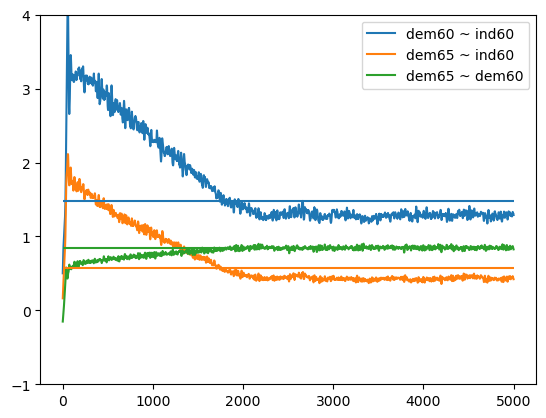

In [13]:
plt.plot(range(niter), coefs[:,0], label = "dem60 ~ ind60")
plt.plot(range(niter), coefs[:,1], label = "dem65 ~ ind60")
plt.plot(range(niter), coefs[:,2], label = "dem65 ~ dem60")
plt.hlines(lavaan_coefs, xmin = 0, xmax = niter, colors = ["C0", "C1", "C2"])
plt.ylim(-1, 4)
plt.legend()

In [14]:
# change loss function to negative log likelihood
sample_cov = torch.cov(torch.t(x))
model = sem2(formula)
optimizer = torch.optim.Adam(model.parameters(), lr=5e-2)
model.train()
niter = 5000
coefs = np.zeros([niter, 3])
for i in range(niter):
    optimizer.zero_grad()
    model_sample = model(x.size(0) * 10)[:, observed_index]
    model_cov = torch.cov(torch.t(model_sample))
    loss = torch.log(torch.det(model_cov)) + torch.trace(sample_cov @ torch.inverse(model_cov))
    loss.backward()
    optimizer.step()
    ind60_scale = model.layer["x1"].weight[0][0]
    dem60_scale = model.layer["y1"].weight[0][0]
    dem65_scale = model.layer["y5"].weight[0][0]
    coefs[i,:] = torch.tensor([model.layer["dem60"].weight[0][0] / ind60_scale * dem60_scale,
                               model.layer["dem65"].weight[0][0] / ind60_scale * dem65_scale,
                               model.layer["dem65"].weight[0][1] / dem60_scale * dem65_scale]).numpy()
    if i == 0 or (i + 1) % 1000 == 0:
        print(f'Iter {i + 1} | loss: {loss.item():.4f}, s1: {s1.item():.4f}, s2: {s2.item():.4f}')
        print(coefs[i, :])

Iter 1 | loss: 2126.2458, s1: 12.5177, s2: 12.6640
[-1.69843140e+01  3.03123593e+00 -1.97144970e-03]
Iter 1000 | loss: 22.4724, s1: 12.5177, s2: 12.6640
[1.26825511 0.66044825 0.86544889]
Iter 2000 | loss: 22.0797, s1: 12.5177, s2: 12.6640
[1.36993194 0.53474945 0.84112287]
Iter 3000 | loss: 22.1230, s1: 12.5177, s2: 12.6640
[1.41964138 0.48238528 0.82388628]
Iter 4000 | loss: 22.0224, s1: 12.5177, s2: 12.6640
[1.40753877 0.39912856 0.85592747]
Iter 5000 | loss: 22.0066, s1: 12.5177, s2: 12.6640
[1.45643425 0.4509849  0.86925769]


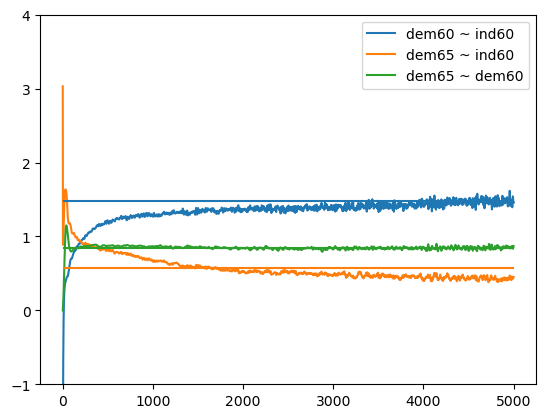

In [15]:
plt.plot(range(niter), coefs[:,0], label = "dem60 ~ ind60")
plt.plot(range(niter), coefs[:,1], label = "dem65 ~ ind60")
plt.plot(range(niter), coefs[:,2], label = "dem65 ~ dem60")
plt.hlines(lavaan_coefs, xmin = 0, xmax = niter, colors = ["C0", "C1", "C2"])
plt.ylim(-1, 4)
plt.legend()

In [16]:
x = dataset[:, [var_names.index(var) for var in observed_var]]
sd = torch.std(x, dim = 0)
print(sd)
x_normalized = torch.zeros_like(x)
for i in range(x.size(1)):
    x_normalized[:,i] = x[:,i] / sd[i]

tensor([2.6227, 3.9471, 3.2809, 3.3495, 2.6126, 3.3727, 3.2862, 3.2456, 0.7329,
        1.5107, 1.4057])


In [17]:
# Try normalizing before energy loss minimization
model = sem2(formula)
optimizer = torch.optim.Adam(model.parameters(), lr=5e-3)
model.train()
niter = 10000
coefs = np.zeros([niter, 3])
for i in range(niter):
    optimizer.zero_grad()
    sample = model(x.size(0) * 100)[:, observed_index]
    loss, s1, s2 = energy_loss(x_normalized, sample)
    loss.backward()
    optimizer.step()
    ind60_scale = model.layer["x1"].weight[0][0] * sd[var_names.index("x1")]
    dem60_scale = model.layer["y1"].weight[0][0] * sd[var_names.index("y1")]
    dem65_scale = model.layer["y5"].weight[0][0] * sd[var_names.index("y5")]
    coefs[i,:] = torch.tensor([model.layer["dem60"].weight[0][0] / ind60_scale * dem60_scale,
                               model.layer["dem65"].weight[0][0] / ind60_scale * dem65_scale,
                               model.layer["dem65"].weight[0][1] / dem60_scale * dem65_scale]).numpy()
    if i == 0 or (i + 1) % 1000 == 0:
        print(f'Iter {i + 1} | loss: {loss.item():.4f}, s1: {s1.item():.4f}, s2: {s2.item():.4f}')
        print(coefs[i, :])

Iter 1 | loss: 9.1554, s1: 10.2467, s2: 2.1826
[ 3.0292449   2.0418222  -0.29650888]
Iter 1000 | loss: 3.0291, s1: 6.3202, s2: 6.5821
[-5.04931482e-03  3.53521347e-01  6.41286993e+00]
Iter 2000 | loss: 2.2181, s1: 4.4786, s2: 4.5210
[1.68036163 0.74197459 0.8810153 ]
Iter 3000 | loss: 2.1750, s1: 4.4154, s2: 4.4810
[1.65494013 0.6107949  0.83491391]
Iter 4000 | loss: 2.1822, s1: 4.4383, s2: 4.5122
[1.75425923 0.66383892 0.86429137]
Iter 5000 | loss: 2.2011, s1: 4.4534, s2: 4.5047
[1.64974737 0.60950893 0.83729118]
Iter 6000 | loss: 2.1941, s1: 4.4402, s2: 4.4922
[1.82082915 0.69209468 0.84976697]
Iter 7000 | loss: 2.1837, s1: 4.4294, s2: 4.4913
[1.60274661 0.61667502 0.83011383]
Iter 8000 | loss: 2.1905, s1: 4.4063, s2: 4.4318
[1.74481142 0.6469698  0.83629155]
Iter 9000 | loss: 2.2035, s1: 4.4255, s2: 4.4440
[1.64902925 0.64220995 0.82402599]
Iter 10000 | loss: 2.1754, s1: 4.4133, s2: 4.4759
[1.77729559 0.71510416 0.79163742]


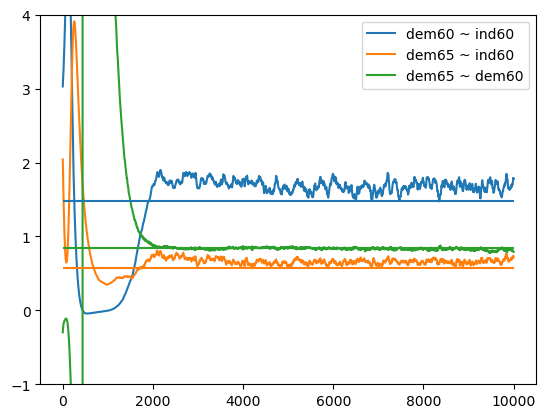

In [18]:
plt.plot(range(niter), coefs[:,0], label = "dem60 ~ ind60")
plt.plot(range(niter), coefs[:,1], label = "dem65 ~ ind60")
plt.plot(range(niter), coefs[:,2], label = "dem65 ~ dem60")
plt.hlines(lavaan_coefs, xmin = 0, xmax = niter, colors = ["C0", "C1", "C2"])
plt.ylim(-1, 4)
plt.legend()

In [19]:
# Try smaller sample size to approximate energy loss
model = sem2(formula)
optimizer = torch.optim.Adam(model.parameters(), lr=2e-3)
model.train()
niter = 50000
coefs = np.zeros([niter, 3])
for i in range(niter):
    optimizer.zero_grad()
    sample = model(x.size(0) * 2)[:, observed_index]
    loss, s1, s2 = energy_loss(x_normalized, sample)
    loss.backward()
    optimizer.step()
    ind60_scale = model.layer["x1"].weight[0][0] * sd[var_names.index("x1")]
    dem60_scale = model.layer["y1"].weight[0][0] * sd[var_names.index("y1")]
    dem65_scale = model.layer["y5"].weight[0][0] * sd[var_names.index("y5")]
    coefs[i,:] = torch.tensor([model.layer["dem60"].weight[0][0] / ind60_scale * dem60_scale,
                               model.layer["dem65"].weight[0][0] / ind60_scale * dem65_scale,
                               model.layer["dem65"].weight[0][1] / dem60_scale * dem65_scale]).numpy()
    if i == 0 or (i + 1) % 1000 == 0:
        print(f'Iter {i + 1} | loss: {loss.item():.4f}, s1: {s1.item():.4f}, s2: {s2.item():.4f}')
        print(coefs[i, :])

Iter 1 | loss: 9.2951, s1: 10.2018, s2: 1.8134
[ 1.12488532  2.1959672  -0.10591138]
Iter 1000 | loss: 4.5810, s1: 8.8515, s2: 8.5409
[2.99299574 2.77873111 0.33888072]
Iter 2000 | loss: 2.9964, s1: 6.5202, s2: 7.0476
[0.58629853 0.57649255 0.28618413]
Iter 3000 | loss: 2.7896, s1: 5.5616, s2: 5.5441
[0.56754845 0.55494452 0.365345  ]
Iter 4000 | loss: 2.2942, s1: 4.7043, s2: 4.8201
[1.27645278 1.26589513 0.4989365 ]
Iter 5000 | loss: 2.1401, s1: 4.4520, s2: 4.6236
[2.13326621 1.96079457 0.57338351]
Iter 6000 | loss: 2.1289, s1: 4.5681, s2: 4.8784
[2.46436834 1.90872204 0.5919295 ]
Iter 7000 | loss: 2.3745, s1: 4.5422, s2: 4.3354
[2.42844582 1.78488076 0.61895341]
Iter 8000 | loss: 2.1808, s1: 4.4955, s2: 4.6295
[2.11297226 1.51233804 0.64459729]
Iter 9000 | loss: 2.3723, s1: 4.6085, s2: 4.4725
[1.80123878 1.32679641 0.710886  ]
Iter 10000 | loss: 2.0754, s1: 4.3428, s2: 4.5348
[1.83969736 1.2377485  0.7489745 ]
Iter 11000 | loss: 2.4338, s1: 4.6380, s2: 4.4083
[1.8851037  1.10952222 0

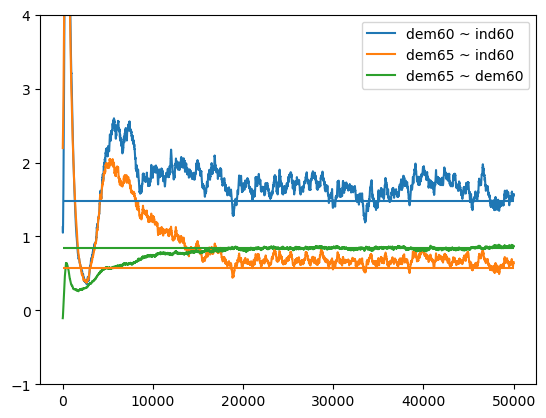

In [20]:
plt.plot(range(niter), coefs[:,0], label = "dem60 ~ ind60")
plt.plot(range(niter), coefs[:,1], label = "dem65 ~ ind60")
plt.plot(range(niter), coefs[:,2], label = "dem65 ~ dem60")
plt.hlines(lavaan_coefs, xmin = 0, xmax = niter, colors = ["C0", "C1", "C2"])
plt.ylim(-1, 4)
plt.legend()